# Parte 5 – Comparación entre condiciones y desempeño

Reproducción del artículo en A9 y B9, generalización a todos los sujetos (Wilcoxon, Friedman, corrección de Holm, tamaños del efecto) y relación de la potencia beta con aciertos y tiempo de reacción (lineal vs. U invertida).

**Unidad de análisis.** Un valor por sujeto y condición: la mediana de la potencia de sus épocas válidas en esa condición (Parte 3). Las comparaciones son dentro de cada sujeto, porque el nivel absoluto de beta depende del contacto de cada electrodo y no se puede comparar entre personas. Cada experimento se analiza por separado.

**Qué épocas y canales entran.** Los mismos que en la tabla de potencias: beta usa `usable_beta` en los 4 canales; theta, alfa y theta/beta usan `usable`, en la práctica solo AF7 y AF8 (Parte 2). Una celda sujeto × condición cuenta si tiene al menos 20 épocas válidas.

**Pruebas.**
- Dos condiciones pareadas: Wilcoxon de rangos con signo. Con unos 10 sujetos no se puede suponer normalidad.
- Tres o más (sesiones de un experimento): Friedman y, como comparación planeada, Wilcoxon de cada sesión contra la sesión sin estímulo.
- Holm dentro de cada familia de pruebas (los canales de una misma comparación, o las sesiones de un mismo canal).
- Tamaño del efecto: r = Z / √N (Wilcoxon) y W de Kendall (Friedman). Se informa también la mediana del cociente entre condiciones y cuántos sujetos suben.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from eeg_nback import datos, estadistica, potencias
from eeg_nback.config import load_config

warnings.filterwarnings('ignore', category=RuntimeWarning)
cfg = load_config()
OUT = cfg['OUTPUT_DIR']
SEED = cfg['SEED']
CANALES = cfg['CANALES']
FRONTALES = ['AF7', 'AF8']

## 1. Verificación con datos sintéticos

Antes de usar el EEG se prueban las funciones con datos de los que se conoce la respuesta.

### 1.1 Wilcoxon: falsos positivos y sensibilidad

Se simulan 10 sujetos con un valor en dos condiciones. El nivel de cada sujeto es distinto (como pasa con el contacto de cada electrodo) y el cambio entre condiciones es un factor multiplicativo con variación entre sujetos. Sin efecto, la prueba tiene que dar p < 0,05 en cerca del 5 % de los casos.

La variación entre sujetos del cociente se toma del EEG: el desvío de log10 del cociente 3-back / 1-back de beta es de unos 0,05 (sección 3).

In [3]:
def simular(rng, n=10, efecto=1.0, desvio=0.05):
    nivel = 10 ** rng.normal(1.3, 0.4, n)                 # µV², distinto en cada sujeto
    a = pd.Series(nivel)
    b = pd.Series(nivel * efecto * 10 ** rng.normal(0, desvio, n))
    return a, b

def tasa_significativa(efecto, n_rep=2000, **kw):
    rng = np.random.default_rng(SEED)
    return np.mean([estadistica.wilcoxon_pareado(*simular(rng, efecto=efecto, **kw))['p'] < 0.05
                    for _ in range(n_rep)]) * 100

efectos = [1.0, 1.02, 1.05, 1.10]
pd.DataFrame({'p < 0,05 [%]': [tasa_significativa(e) for e in efectos]},
             index=pd.Index([f'×{e:.2f}' for e in efectos], name='cambio simulado')).round(1)

,"p < 0,05 [%]"
cambio simulado,
×1.00,5.4
×1.02,7.6
×1.05,19.8
×1.10,56.9


> **Resultado:** sin efecto, la prueba da p < 0,05 en el 5,4 % de los casos (se espera 5 %). Con 10 sujetos y la variación entre sujetos del EEG (desvío de 0,04 a 0,06 en log10 del cociente 3-back / 1-back, según el canal), un cambio de ×1,10 se detecta en el 56,9 % de los casos y uno de ×1,05 en el 19,8 %. Es el límite de lo que se puede ver con esta cantidad de sujetos: un resultado no significativo no demuestra que no haya efecto, sobre todo si es menor al 10 %.

### 1.2 Lineal contra cuadrático

Se generan 500 bloques con una relación conocida entre una variable x y el desempeño y, más ruido: una recta, una U invertida y ninguna relación. El AIC tiene que preferir el modelo correcto, y el coeficiente cuadrático tiene que salir negativo y significativo solo con la U invertida.

In [4]:
rng = np.random.default_rng(SEED)
x = rng.standard_normal(500)
casos = {'recta': 0.3 * x, 'U invertida': -0.3 * x ** 2, 'sin relación': 0 * x}
filas = {}
for nombre, y in casos.items():
    r = estadistica.lineal_vs_cuadratico(x, y + rng.standard_normal(500))
    filas[nombre] = {k: r[k] for k in ['b_lineal', 'p_lineal', 'c', 'p_c', 'delta_aic']}
pd.DataFrame(filas).T.round(4)

,b_lineal,p_lineal,c,p_c,delta_aic
recta,0.2937,0.0000,-0.0438,0.0883,-0.9250
U invertida,-0.0342,0.4543,-0.2848,0.0000,-112.0063
sin relación,0.0344,0.4210,-0.0085,0.7484,1.8964


> **Resultado:** con la recta, la pendiente sale significativa, el coeficiente cuadrático no (p = 0,088) y el AIC prefiere el modelo lineal por poco (delta_aic = −0,9; una diferencia menor a 2 se considera empate). Con la U invertida, c = −0,28 (se simuló −0,3), p < 0,0001 y el AIC prefiere el cuadrático por 112. Sin relación, ninguno de los dos coeficientes es significativo y el AIC prefiere el lineal (delta_aic = +1,9, el costo del parámetro extra). Las funciones distinguen los tres casos.

## 2. Datos

Se usa `outputs/potencias_epocas.csv` (generada por `scripts/generar_potencias.py`): una fila por época y canal, con la potencia de cada banda y las marcas de la Parte 2. Se agregan:
- `fase`: tarea (1-back o 3-back) o pausa;
- `theta_beta`: el cociente por época, como en la Parte 3;
- `sin_deflexion`: épocas que pasan también el rechazo de 1 a 40 Hz. Sirve de control en TP9 y TP10 (Parte 4, sección 4.1).

In [5]:
pot = estadistica.agregar_fase(pd.read_csv(OUT / 'potencias_epocas.csv'))
pot['theta_beta'] = pot.theta / pot.beta
pot['sin_deflexion'] = pot.usable & pot.usable_beta

sujetos = datos.listar_sujetos()
bloques = pd.concat([datos.tabla_bloques(datos.cargar_nback(s.ruta)).assign(sujeto=s.sujeto)
                     for s in sujetos.itertuples()], ignore_index=True)

cob = potencias.cobertura(pot)
print('Sujetos que cumplen la regla de canales (Parte 2):')
cob.groupby('canal').sum().loc[CANALES].T

Sujetos que cumplen la regla de canales (Parte 2):


canal,TP9,AF7,AF8,TP10
lentas,3,11,17,3
beta,18,17,19,18


## 3. Reproducción del artículo en A9 y B9

El artículo analiza un sujeto por experimento: en A9 la potencia beta aumenta con los tres tipos de música respecto de la sesión sin música (entre 27 % y 47 %), y en B9 disminuye después de oler el perfume.

Con un solo sujeto no hay pares de sujetos: se comparan las épocas de tarea de cada sesión con las de la sesión sin estímulo, con la prueba de Mann-Whitney (la versión de Wilcoxon para muestras independientes). Las épocas de una misma sesión no son del todo independientes (están correlacionadas en el tiempo, Parte 4), así que el p-valor es orientativo; lo importante es el cociente.

A9 solo conserva TP9 y AF7 para beta (Parte 2). El artículo mira TP9 y TP10.

In [6]:
def reproducir(sujeto, referencia):
    s = pot[(pot.sujeto == sujeto) & pot.usable_beta & (pot.fase == 'tarea')]
    s = s[[cob.loc[(sujeto, c), 'beta'] for c in s.canal]]
    filas = []
    for canal, g in s.groupby('canal', sort=False):
        ref = g[g.condicion == referencia].beta
        for cond, h in g.groupby('condicion', sort=False):
            if cond == referencia:
                continue
            filas.append({'canal': canal, 'condicion': cond, 'n_ref': len(ref), 'n': len(h),
                          'cociente': h.beta.median() / ref.median(),
                          'p': stats.mannwhitneyu(h.beta, ref).pvalue})
    return pd.DataFrame(filas)

reproducir('A9', 'sin_musica').round(4)

,canal,condicion,n_ref,n,cociente,p
0,TP9,relajante,259,284,1.5184,0.0
1,TP9,estimulante,259,267,1.6768,0.0
2,TP9,ia,259,258,2.5268,0.0
3,AF7,relajante,322,327,2.5836,0.0
4,AF7,estimulante,322,319,2.8495,0.0
5,AF7,ia,322,316,4.8869,0.0


In [7]:
reproducir('B9', 'basal').round(4)

,canal,condicion,n_ref,n,cociente,p
0,TP9,perfume,318,331,0.3563,0.0
1,TP9,cafe,318,323,0.7037,0.0
2,AF7,perfume,338,342,0.4053,0.0
3,AF7,cafe,338,336,0.7663,0.0
4,AF8,perfume,340,335,0.5190,0.0
5,AF8,cafe,340,336,0.7042,0.0
6,TP10,perfume,335,324,0.3452,0.0
7,TP10,cafe,335,330,0.6986,0.0


> **Resultado:** en **A9**, beta aumenta con los tres tipos de música respecto de la sesión sin música: ×1,5 (relajante), ×1,7 (estimulante) y ×2,5 (IA) en TP9, y todavía más en AF7. La dirección coincide con el artículo, pero el aumento es mayor que el 27-47 % que informa. En **B9**, beta disminuye después del perfume en los 4 canales (×0,35 a ×0,52), como en el artículo, y también con el café (×0,70 a ×0,77).
>
> Hay que tener en cuenta dos cosas. Todas las sesiones se hicieron en el mismo orden (sin música, relajante, estimulante, IA; basal, perfume, café), así que dentro de un sujeto no se puede separar el efecto del estímulo del paso del tiempo (cambio de contacto de los electrodos secos, cansancio, práctica). Además, en A9 la sesión sin música tiene una beta muy baja en AF7 (mediana 6,0 µV², contra 15,6 a 29,5 en las otras), lo que sugiere un cambio de contacto. Por eso hace falta ver si el resultado se repite en los demás sujetos (sección 5).

## 4. Carga cognitiva

### 4.1 Tarea contra pausa (beta)

La hipótesis, tomada del artículo, es que beta es mayor en la tarea que en la pausa. La Parte 4 encontró lo contrario en TP9 y TP10, con parte de la diferencia explicada por las deflexiones. Acá se prueba con Wilcoxon sobre los sujetos, con todas las épocas `usable_beta` y con las épocas sin deflexión.

In [8]:
tp = estadistica.comparar_canales(pot, CANALES, 'pausa', 'tarea', por='fase')
tp_limpias = estadistica.comparar_canales(pot, CANALES, 'pausa', 'tarea', por='fase',
                                          valida='sin_deflexion', regla='beta')
pd.concat({'todas las épocas usable_beta': tp.set_index('canal'),
           'solo sin deflexión': tp_limpias.set_index('canal')}, axis=1).round(4)

todas las épocas usable_beta                                        \
                                 n cociente n_sube     W       p       r   
canal                                                                      
TP9                             18   0.8180      2  13.0  0.0007 -0.7442   
AF7                             17   0.9470      4  46.0  0.1594 -0.3502   
AF8                             19   1.0289     12  77.0  0.4900  0.1662   
TP10                            18   0.8410      3  13.0  0.0007 -0.7442   

              solo sin deflexión                                                
       p_holm                  n cociente n_sube     W       p       r  p_holm  
canal                                                                           
TP9    0.0027                 15   0.9097      3  17.0  0.0125 -0.6306  0.0498  
AF7    0.3188                 17   0.9941      8  67.0  0.6777 -0.1091  0.6777  
AF8    0.4900                 19   1.0286     13  64.0  0.2253  0.2862  0.4506  
TP10   0.0027                 16   0.9357      5  29.0  0.0443 -0.5042  0.1329

`cociente` es la mediana entre sujetos de tarea / pausa; `n_sube` es cuántos sujetos tienen más beta en la tarea; `r` es positivo si beta tiende a ser mayor en la tarea.

> **Resultado:** beta **no** es mayor en la tarea. En TP9 y TP10 es menor (cociente 0,82 y 0,84; solo 2 y 3 de 18 sujetos tienen más beta en la tarea; p = 0,0007, p corregido 0,003, r = −0,74). En AF7 y AF8 no hay diferencia. Con las épocas sin deflexión la reducción en los temporales se achica (×0,91 en TP9 y ×0,94 en TP10) y sigue siendo significativa en TP9 (p corregido 0,0498), pero no en TP10 (0,13). Es lo mismo que mostró la Parte 4 con Lomb: el ciclo tarea-pausa existe, pero con beta más baja en la tarea, y una parte se debe a las deflexiones de la pausa.

### 4.2 1-back contra 3-back

Hipótesis del anteproyecto: al pasar de 1-back a 3-back aumenta theta en los canales frontales y disminuye alfa. Para beta no hay una hipótesis de dirección. Se usan solo las épocas de tarea. Holm se aplica dentro de cada banda, sobre sus canales.

In [9]:
tarea = pot[pot.fase == 'tarea']
pruebas = {'beta': ('beta', 'usable_beta', CANALES), 'theta': ('theta', 'usable', FRONTALES),
           'alfa': ('alfa', 'usable', FRONTALES), 'theta/beta': ('theta_beta', 'usable', FRONTALES)}
carga = pd.concat({nombre: estadistica.comparar_canales(tarea, can, '1-back', '3-back', columna=col, valida=val)
                   .set_index('canal') for nombre, (col, val, can) in pruebas.items()})
carga.round(4)

n  cociente  n_sube     W       p       r  p_holm
           canal                                                    
beta       TP9    18    0.9869       9  82.0  0.8986 -0.0359  1.0000
           AF7    17    0.9637       8  56.0  0.3529 -0.2354  1.0000
           AF8    19    0.9750       7  73.0  0.3955 -0.2031  1.0000
           TP10   18    0.9877       7  64.0  0.3692 -0.2207  1.0000
theta      AF7    11    1.2091       9   5.0  0.0098  0.7506  0.0133
           AF8    17    1.1795      12  21.0  0.0067  0.6372  0.0133
alfa       AF7    11    1.0604      10   4.0  0.0068  0.7774  0.0137
           AF8    17    1.0065       9  66.0  0.6441  0.1206  0.6441
theta/beta AF7    11    1.2683       9  12.0  0.0674  0.5630  0.1348
           AF8    17    1.2368      12  47.0  0.1743  0.3387  0.1743

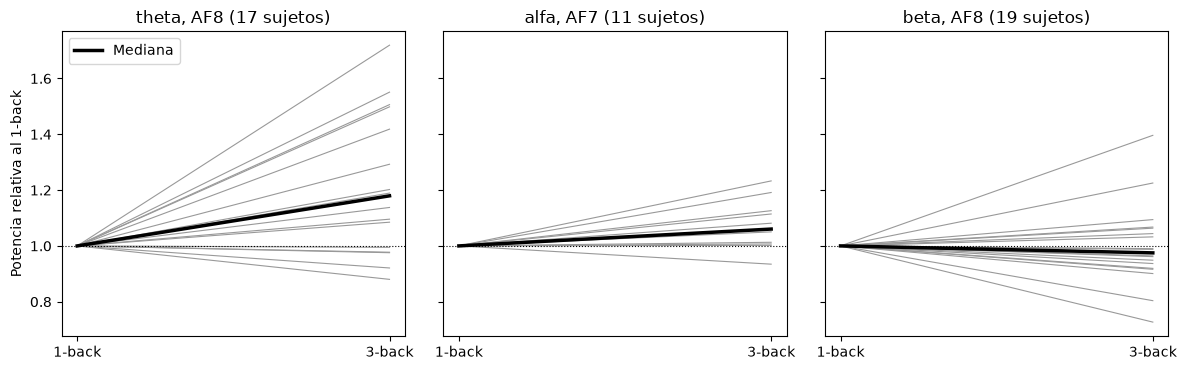

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (nombre, canal) in zip(axs, [('theta', 'AF8'), ('alfa', 'AF7'), ('beta', 'AF8')]):
    col, val, _ = pruebas[nombre]
    piv = estadistica.tabla_por_condicion(tarea, canal, columna=col, valida=val).dropna()
    for v in piv.itertuples():
        ax.plot([0, 1], [1, v._2 / v._1], color='0.6', lw=0.8)
    ax.plot([0, 1], [1, (piv['3-back'] / piv['1-back']).median()], 'k', lw=2.5, label='Mediana')
    ax.axhline(1, color='k', ls=':', lw=0.8)
    ax.set_xticks([0, 1], ['1-back', '3-back'])
    ax.set_title(f'{nombre}, {canal} ({len(piv)} sujetos)')
axs[0].set_ylabel('Potencia relativa al 1-back')
axs[0].legend()
plt.tight_layout()

> **Resultado:** **theta aumenta en el 3-back** en los dos canales frontales (×1,21 en AF7 y ×1,18 en AF8; 9 de 11 y 12 de 17 sujetos; p corregido 0,013 en los dos; r = 0,75 y 0,64), como se esperaba. **Alfa no disminuye**: en AF8 no cambia y en AF7 aumenta un poco (×1,06, 10 de 11 sujetos, p corregido 0,014), lo contrario de la hipótesis. **Beta no cambia** con la carga en ningún canal (cocientes entre 0,96 y 0,99, p > 0,35). El cociente theta/beta tiende a subir (×1,24 a ×1,27), pero no llega a ser significativo.
>
> AF7 tiene solo 11 sujetos para las bandas lentas, y TP9 y TP10 no se pueden usar (Parte 2). El aumento de alfa en AF7 es chico y se apoya en pocos sujetos; con la sensibilidad de la sección 1.1, un efecto de este tamaño solo se detecta si es muy consistente entre sujetos, que es lo que pasa acá (10 de 11).

## 5. Estímulos

Solo épocas de tarea, para que la comparación no dependa de cuántas pausas válidas tiene cada sesión. Cada sesión se compara con la sesión sin estímulo de su experimento.

Friedman necesita los sujetos que tienen todas las sesiones; los Wilcoxon de a pares usan los que tienen las dos sesiones de cada par. Los pares se informan aunque Friedman no dé significativo, porque son las comparaciones planeadas en el anteproyecto (cada estímulo contra la sesión sin estímulo), pero se interpretan junto con Friedman.

### 5.1 Experimento 1: música

In [11]:
exp1 = pot[pot.experimento == 1]
fr1, pares1 = estadistica.comparar_sesiones(exp1, CANALES, 'sin_musica')
fr1.round(4)

,canal,chi2,p,n,W_kendall,p_holm
0,TP9,2.7333,0.4346,9,0.1012,1.0000
1,AF7,3.4000,0.3340,9,0.1259,1.0000
2,AF8,4.6000,0.2035,9,0.1704,0.8142
3,TP10,2.7000,0.4402,8,0.1125,1.0000


In [12]:
pares1.round(4)

,canal,condicion,n,cociente,n_sube,W,p,r,p_holm
0,TP9,estimulante,9,0.8980,3,18.0,0.6523,-0.1777,1.0000
1,TP9,ia,9,0.9303,3,17.0,0.5703,-0.2172,1.0000
2,TP9,relajante,9,0.9668,3,19.0,0.7344,-0.1382,1.0000
3,AF7,estimulante,9,0.7324,3,12.0,0.2500,-0.4146,0.7500
4,AF7,ia,9,1.2807,6,13.0,0.3008,0.3752,0.7500
5,AF7,relajante,9,1.0229,5,20.0,0.8203,0.0987,0.8203
6,AF8,estimulante,9,0.7105,2,8.0,0.0977,-0.5726,0.2930
7,AF8,ia,9,1.1753,5,17.0,0.5703,0.2172,1.0000
8,AF8,relajante,9,0.9808,3,18.0,0.6523,-0.1777,1.0000
9,TP10,estimulante,8,0.9435,3,13.0,0.5469,-0.2475,1.0000


> **Resultado:** en el experimento 1 la música **no cambia beta** a nivel de grupo. Friedman no da significativo en ningún canal (p entre 0,20 y 0,44; W de Kendall entre 0,10 y 0,17) y ninguna comparación contra la sesión sin música lo es, ni antes ni después de Holm. Los cocientes van para los dos lados según el canal y el tipo de música, y en la mayoría de los pares solo 2 o 3 de 9 sujetos suben. Lo que el artículo muestra en A9 (y que se reproduce en la sección 3) no se generaliza.
>
> Solo 8 o 9 sujetos tienen las cuatro sesiones en cada canal, así que, según la sección 1.1, un efecto menor al 10 % no se podría detectar. Pero el artículo informa aumentos de 27 a 47 %, y eso sí se vería.

### 5.2 Experimento 2: perfume y café

Hipótesis: el café modula beta y baja el cociente theta/beta; el perfume tiene un efecto menor y más variable. Se agrega el control sin deflexión, porque en la Parte 3 la profundidad de las deflexiones cambiaba entre sesiones del experimento 2 (más profundas con café).

In [13]:
exp2 = pot[pot.experimento == 2]
fr2, pares2 = estadistica.comparar_sesiones(exp2, CANALES, 'basal')
fr2.round(4)

,canal,chi2,p,n,W_kendall,p_holm
0,TP9,6.8889,0.0319,9,0.3827,0.1277
1,AF7,6.7500,0.0342,8,0.4219,0.1277
2,AF8,5.6000,0.0608,10,0.2800,0.1277
3,TP10,4.2000,0.1225,10,0.2100,0.1277


In [14]:
pares2.round(4)

,canal,condicion,n,cociente,n_sube,W,p,r,p_holm
0,TP9,cafe,9,1.3116,7,8.0,0.0977,0.5726,0.1953
1,TP9,perfume,9,0.8688,3,16.0,0.4961,-0.2567,0.4961
2,AF7,cafe,8,1.6917,7,3.0,0.0391,0.7426,0.0781
3,AF7,perfume,8,0.9057,4,16.0,0.8438,-0.0990,0.8438
4,AF8,cafe,10,1.5426,7,10.0,0.0840,0.5641,0.1680
5,AF8,perfume,10,1.0080,5,25.0,0.8457,-0.0806,0.8457
6,TP10,cafe,10,1.1852,6,15.0,0.2324,0.4029,0.4648
7,TP10,perfume,10,0.9461,3,21.0,0.5566,-0.2095,0.5566


In [15]:
fr2_tb, pares2_tb = estadistica.comparar_sesiones(exp2, FRONTALES, 'basal', columna='theta_beta', valida='usable')
fr2_l, pares2_l = estadistica.comparar_sesiones(exp2, CANALES, 'basal', valida='sin_deflexion', regla='beta')
pd.concat({'theta/beta': pares2_tb.set_index(['canal', 'condicion']),
           'beta, solo sin deflexión': pares2_l.set_index(['canal', 'condicion'])})[
    ['n', 'cociente', 'n_sube', 'p', 'r', 'p_holm']].round(4)

n  cociente  n_sube       p  \
                         canal condicion                                 
theta/beta               AF7   cafe        6    1.0593     3.0  0.8438   
                               perfume     6    1.3799     4.0  0.2188   
                         AF8   cafe        9    0.9978     4.0  1.0000   
                               perfume     9    1.2477     6.0  0.0977   
beta, solo sin deflexión TP9   cafe        5    1.0818     3.0  0.6250   
                               perfume     4       NaN     NaN     NaN   
                         AF7   cafe        8    1.7071     7.0  0.0391   
                               perfume     8    0.8957     3.0  0.9453   
                         AF8   cafe       10    1.5274     7.0  0.0645   
                               perfume    10    0.9880     5.0  1.0000   
                         TP10  cafe        6    0.8827     2.0  1.0000   
                               perfume     6    1.0290     3.0  0.5625   

                                               r  p_holm  
                         canal condicion                  
theta/beta               AF7   cafe      -0.1284  0.8438  
                               perfume    0.5563  0.4375  
                         AF8   cafe      -0.0197  1.0000  
                               perfume    0.5726  0.1953  
beta, solo sin deflexión TP9   cafe       0.3015  0.6250  
                               perfume       NaN     NaN  
                         AF7   cafe       0.7426  0.0781  
                               perfume   -0.0495  0.9453  
                         AF8   cafe       0.5963  0.1289  
                               perfume   -0.0161  1.0000  
                         TP10  cafe      -0.0428  1.0000  
                               perfume    0.2996  1.0000

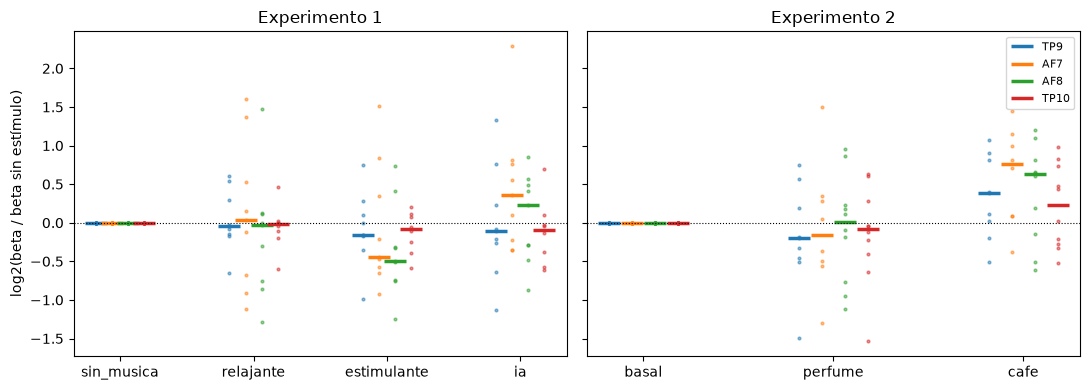

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (e, ref, orden) in zip(axs, [(exp1, 'sin_musica', ['sin_musica', 'relajante', 'estimulante', 'ia']),
                                     (exp2, 'basal', ['basal', 'perfume', 'cafe'])]):
    tarea_e = e[e.fase == 'tarea']
    for i, canal in enumerate(CANALES):
        piv = estadistica.tabla_por_condicion(tarea_e, canal, por='condicion')[orden]
        rel = np.log2(piv.div(piv[ref], axis=0))
        x = np.arange(len(orden)) + (i - 1.5) * 0.12
        ax.plot(np.tile(x, (len(rel), 1)).T, rel.T.values, '.', color=f'C{i}', ms=4, alpha=0.5)
        ax.plot(x, rel.median(), '_', color=f'C{i}', ms=16, mew=2.5, label=canal)
    ax.axhline(0, color='k', ls=':', lw=0.8)
    ax.set_xticks(range(len(orden)), orden)
axs[0].set_ylabel(f'log2(beta / beta sin estímulo)')
axs[0].set_title('Experimento 1')
axs[1].set_title('Experimento 2')
axs[1].legend(fontsize=8)
plt.tight_layout()

> **Resultado:** el **café** es el único estímulo con una tendencia clara: beta sube en 6 o 7 de los 8 a 10 sujetos de cada canal (×1,31 en TP9, ×1,69 en AF7, ×1,54 en AF8, ×1,19 en TP10). Friedman da p = 0,03 en TP9 y AF7 y p = 0,06 en AF8, pero después de Holm sobre los 4 canales ninguno es significativo (p = 0,13). En la comparación con la sesión basal, AF7 da p = 0,039 (0,078 con Holm). El **perfume** no cambia beta a nivel de grupo (cocientes de 0,87 a 1,01), aunque en B9 la bajaba. El cociente **theta/beta** no baja con el café (×1,06 y ×1,00).
>
> El control sin deflexión da lo mismo en los frontales (×1,71 en AF7 y ×1,53 en AF8), así que la tendencia del café no se debe a que las deflexiones sean más profundas en esa sesión. En TP9 y TP10 quedan solo 5 o 6 sujetos y el aumento desaparece.
>
> Como el café es siempre la última sesión, después de 30 min de descanso, el aumento puede deberse también al momento del registro. Sin una sesión de control en la misma posición no se puede separar.

### 5.3 ¿Cambia el desempeño entre sesiones?

Para interpretar lo anterior: si un estímulo cambia beta, se espera que también cambie el desempeño. Se usa el porcentaje de aciertos y la mediana del tiempo de reacción de cada sesión, separados por tipo de bloque.

In [17]:
filas = []
for exp, ref in [(1, 'sin_musica'), (2, 'basal')]:
    b = bloques[bloques.sujeto.isin(sujetos[sujetos.experimento == exp].sujeto)]
    for tipo, g in b.groupby('tipo'):
        for medida in ['aciertos', 'rt_mediana']:
            piv = g.groupby(['sujeto', 'condicion'])[medida].median().unstack()
            filas.append({'experimento': exp, 'tipo': tipo, 'medida': medida}
                         | estadistica.friedman(piv)
                         | {f'mediana_{c}': piv[c].median() for c in piv.columns})
desempeno = pd.DataFrame(filas)
desempeno['p_holm'] = desempeno.groupby('experimento').p.transform(estadistica.corregir_holm)
desempeno.round(4)

,experimento,tipo,medida,chi2,p,n,W_kendall,mediana_estimulante,mediana_ia,mediana_relajante,mediana_sin_musica,mediana_basal,mediana_cafe,mediana_perfume,p_holm
0,1,1-back,aciertos,6.1385,0.1051,10,0.2046,0.9318,0.9545,0.9545,0.9545,NaN,NaN,NaN,0.1464
1,1,1-back,rt_mediana,6.9600,0.0732,10,0.2320,461.8750,422.7500,509.5000,559.7500,NaN,NaN,NaN,0.1464
2,1,3-back,aciertos,12.6522,0.0055,10,0.4217,0.8750,0.8636,0.8295,0.8068,NaN,NaN,NaN,0.0218
3,1,3-back,rt_mediana,11.6400,0.0087,10,0.3880,524.5000,478.6250,566.2500,718.1250,NaN,NaN,NaN,0.0262
4,2,1-back,aciertos,1.4483,0.4847,10,0.0724,NaN,NaN,NaN,NaN,0.9432,0.9545,0.9545,0.5451
5,2,1-back,rt_mediana,2.6000,0.2725,10,0.1300,NaN,NaN,NaN,NaN,578.8750,478.2500,530.8750,0.5451
6,2,3-back,aciertos,5.0556,0.0798,10,0.2528,NaN,NaN,NaN,NaN,0.8523,0.9091,0.8864,0.3193
7,2,3-back,rt_mediana,4.2000,0.1225,10,0.2100,NaN,NaN,NaN,NaN,732.2500,696.3750,657.0000,0.3674


> **Resultado:** en el experimento 1 el desempeño en el **3-back** cambia entre sesiones (aciertos: p corregido 0,022; tiempo de reacción: 0,026): la sesión sin música es la peor (81 % de aciertos y 718 ms) y la de música generada por IA, la última, es la mejor en tiempo de reacción (479 ms). En el 1-back no hay diferencia, probablemente porque los aciertos ya están cerca del máximo (95 %). En el experimento 2 el desempeño no cambia entre sesiones.
>
> Como la sesión sin música es siempre la primera, la mejora es compatible con un efecto de práctica, y no necesariamente con la música. Lo importante para este trabajo es que el desempeño cambia entre sesiones sin que cambie beta (sección 5.1): en estos datos, beta no acompaña la mejora del desempeño.

## 6. Potencia beta y desempeño

**Unidad: el bloque.** Cada sesión tiene 16 bloques de 22 estímulos, así que hay hasta 64 bloques por sujeto (48 en el experimento 2). Para cada bloque se calcula la mediana de beta de sus épocas válidas (al menos 10 de 22) y se la compara con el porcentaje de aciertos y la mediana del tiempo de reacción del bloque.

**Por qué se centran los datos.** El nivel de beta depende del sujeto y del contacto del electrodo, y el desempeño depende del sujeto y de la dificultad (los 3-back tienen menos aciertos). Si se juntaran los bloques tal cual, la relación mezclaría diferencias entre personas. Por eso log10(beta), aciertos y tiempo de reacción se pasan a z-score dentro de cada sujeto, canal y tipo de bloque: cada bloque se compara con los demás del mismo sujeto y la misma dificultad.

**Dos pruebas.**
1. Con todos los bloques juntos: modelo lineal contra cuadrático, comparados con el AIC. Los bloques de un mismo sujeto no son independientes, así que los p-valores de este ajuste son orientativos.
2. Por sujeto: se ajusta el modelo cuadrático en cada uno y se prueba con Wilcoxon si el coeficiente c es distinto de 0. Es la prueba principal: cada sujeto aporta un solo valor. Una U invertida da c < 0 en la mayoría de los sujetos.

In [18]:
bb = estadistica.beta_por_bloque(pot, bloques)
bb = estadistica.centrar(bb, ['log_beta', 'aciertos', 'rt_mediana'], ['sujeto', 'canal', 'tipo'])
print(f"{len(bb)} bloques (sujeto, canal), {bb.sujeto.nunique()} sujetos")
print(f"Bloques con 100 % de aciertos: {(bloques.aciertos == 1).mean() * 100:.1f} %")
bloques.groupby('tipo')[['aciertos', 'rt_mediana']].median()

3999 bloques (sujeto, canal), 20 sujetos
Bloques con 100 % de aciertos: 14.2 %


,aciertos,rt_mediana
tipo,,
1-back,0.954545,494.5
3-back,0.863636,626.0


In [19]:
filas = []
for y, nombre in [('z_aciertos', 'aciertos'), ('z_rt_mediana', 'tiempo de reacción')]:
    for canal in CANALES:
        g = bb[bb.canal == canal]
        junto = estadistica.lineal_vs_cuadratico(g.z_log_beta, g[y])
        cs = estadistica.coeficientes_por_sujeto(g, 'z_log_beta', y)
        w = estadistica.wilcoxon_pareado(pd.Series(0.0, index=cs.index), cs.c)
        filas.append({'desempeño': nombre, 'canal': canal, 'bloques': junto['n'],
                      'b_lineal': junto['b_lineal'], 'p_lineal': junto['p_lineal'],
                      'c': junto['c'], 'p_c': junto['p_c'], 'delta_aic': junto['delta_aic'],
                      'sujetos': len(cs), 'c_negativo': int((cs.c < 0).sum()),
                      'c_mediana': cs.c.median(), 'p_c_sujetos': w['p']})
rel = pd.DataFrame(filas)
rel['p_c_sujetos_holm'] = rel.groupby('desempeño').p_c_sujetos.transform(estadistica.corregir_holm)
rel.round(4)

,desempeño,canal,bloques,b_lineal,p_lineal,c,p_c,delta_aic,sujetos,c_negativo,c_mediana,p_c_sujetos,p_c_sujetos_holm
0,aciertos,TP9,999,-0.0808,0.0107,-0.0132,0.5921,1.7119,18,12,-0.0182,0.1540,0.4621
1,aciertos,AF7,958,-0.0172,0.5949,-0.0318,0.1950,0.3143,17,13,-0.0588,0.0638,0.2553
2,aciertos,AF8,1056,0.0015,0.9599,-0.0080,0.7400,1.8895,19,8,0.0269,1.0000,1.0000
3,aciertos,TP10,986,-0.0796,0.0124,0.0025,0.9193,1.9897,18,11,-0.0120,0.2645,0.5291
4,tiempo de reacción,TP9,999,0.0303,0.3384,0.0316,0.2003,0.3537,18,6,0.0500,0.1415,0.4246
5,tiempo de reacción,AF7,958,-0.0467,0.1488,0.0419,0.0871,-0.9373,17,8,0.0337,0.6112,1.0000
6,tiempo de reacción,AF8,1056,-0.0009,0.9755,0.0655,0.0066,-5.3966,19,7,0.0995,0.0728,0.2913
7,tiempo de reacción,TP10,986,0.0465,0.1446,-0.0005,0.9852,1.9997,18,9,0.0058,0.6705,1.0000


**Cómo leer la tabla.** `b_lineal` y `p_lineal` son la pendiente del modelo lineal con todos los bloques juntos (en desvíos de desempeño por desvío de log10 de beta). `c` y `p_c` son el coeficiente cuadrático del mismo ajuste. `delta_aic` es el AIC del cuadrático menos el del lineal: negativo si el término cuadrático vale la pena. Las últimas columnas son la prueba por sujeto.

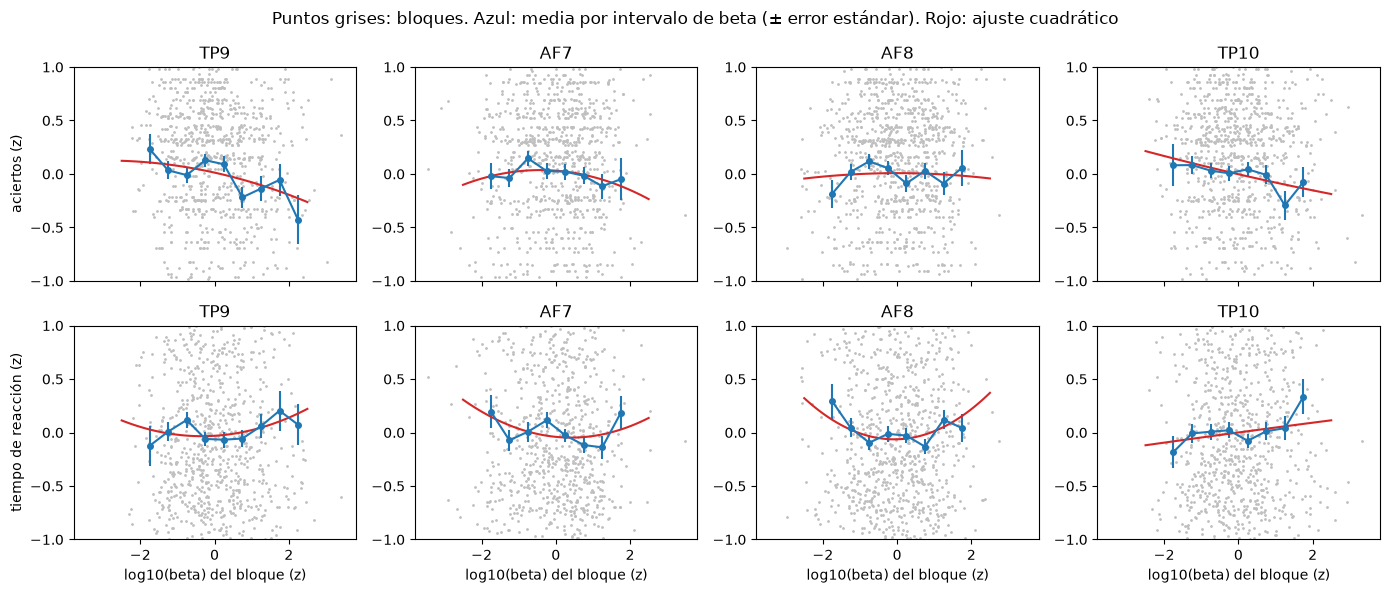

In [20]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
cortes = np.arange(-2.5, 2.6, 0.5)
for fila, (y, nombre) in enumerate([('z_aciertos', 'aciertos (z)'), ('z_rt_mediana', 'tiempo de reacción (z)')]):
    for ax, canal in zip(axs[fila], CANALES):
        g = bb[bb.canal == canal].dropna(subset=[y])
        ax.plot(g.z_log_beta, g[y], '.', color='0.75', ms=2)
        medias = g.groupby(pd.cut(g.z_log_beta, cortes), observed=True)[y].agg(['mean', 'sem', 'size'])
        medias = medias[medias['size'] >= 20]
        centros = [i.mid for i in medias.index]
        ax.errorbar(centros, medias['mean'], medias['sem'], fmt='o-', color='C0', ms=4)
        xs = np.linspace(-2.5, 2.5, 100)
        r = estadistica.lineal_vs_cuadratico(g.z_log_beta, g[y])
        ax.plot(xs, r['a'] + r['b'] * xs + r['c'] * xs ** 2, 'C3', lw=1.5)
        ax.set_ylim(-1, 1)
        ax.set_title(canal)
        if fila == 1:
            ax.set_xlabel('log10(beta) del bloque (z)')
    axs[fila, 0].set_ylabel(nombre)
plt.suptitle('Puntos grises: bloques. Azul: media por intervalo de beta (± error estándar). Rojo: ajuste cuadrático')
plt.tight_layout()

> **Resultado:** **no hay U invertida**. El coeficiente cuadrático por sujeto es negativo en 12 de 18 sujetos en TP9 y en 13 de 17 en AF7, pero no es significativo (p = 0,15 y 0,064 sin corregir; 0,46 y 0,26 con Holm), y en AF8 es negativo en solo 8 de 19. Con todos los bloques juntos, el AIC prefiere el modelo lineal en los 4 canales para los aciertos (delta_aic entre +0,3 y +2,0).
>
> Lo único que aparece es una **relación lineal débil en los temporales**: los bloques con más beta en TP9 y TP10 tienen algo menos de aciertos (pendiente −0,08 desvíos por desvío; p ≈ 0,01, orientativo porque los bloques de un sujeto no son independientes). Es compatible con lo de la sección 4.1: en los temporales, beta alta se asocia más con artefactos que con concentración. En el tiempo de reacción, el único término cuadrático que mejora el AIC es el de AF8 (delta_aic = −5,4), pero con c > 0, es decir una U normal y no invertida, y no se confirma por sujeto (p corregido 0,29).
>
> Los aciertos de un bloque se cuentan sobre 22 estímulos y el 14 % de los bloques tiene 100 %: es una medida gruesa y con techo, lo que hace difícil ver una curva. El artículo encontró la U invertida con un sujeto y con otra medida de activación (la actividad electrodérmica).

## 7. Conclusiones

1. **Verificación.** Wilcoxon da 5,4 % de falsos positivos sin efecto. Con 10 sujetos detecta un cambio de ×1,10 en el 57 % de los casos y uno de ×1,05 en el 20 %. El ajuste lineal contra cuadrático distingue una recta, una U invertida y la falta de relación.
2. **Reproducción del artículo.** En A9, beta aumenta con los tres tipos de música (×1,5 a ×2,5 en TP9), y en B9 disminuye con el perfume (×0,35 a ×0,52). La dirección coincide con el artículo. Pero las sesiones están siempre en el mismo orden, y en A9 la sesión sin música tiene una beta muy baja en AF7, lo que sugiere un cambio de contacto.
3. **Tarea contra pausa.** Beta no es mayor en la tarea: en TP9 y TP10 es menor (×0,82 y ×0,84, p corregido 0,003), y en los frontales no cambia. Sin las épocas con deflexión la diferencia se achica a ×0,91 y ×0,94, y sigue siendo significativa solo en TP9.
4. **Carga cognitiva.** Theta frontal aumenta del 1-back al 3-back (×1,18 a ×1,21, p corregido 0,013), como se esperaba. Alfa no disminuye (en AF7 sube ×1,06). Beta no cambia con la carga.
5. **Música.** No cambia beta a nivel de grupo (Friedman, p > 0,2 en los 4 canales). El resultado del artículo en A9 no se generaliza.
6. **Perfume y café.** El perfume no cambia beta. El café tiende a aumentarla (×1,2 a ×1,7, en 6 o 7 de 8 a 10 sujetos por canal; Friedman p = 0,03 en TP9 y AF7), pero no es significativo después de corregir por los 4 canales. No se debe a las deflexiones, y theta/beta no baja.
7. **Desempeño.** No hay U invertida entre beta y los aciertos o el tiempo de reacción. En los temporales hay una relación lineal débil y negativa con los aciertos. El desempeño mejora en el 3-back a lo largo de las sesiones del experimento 1 sin que beta cambie.

**Limitaciones.** Hay unos 10 sujetos por experimento, así que los efectos menores al 10 % no se pueden detectar. El orden fijo de las sesiones no permite separar el estímulo del tiempo. En TP9 y TP10, beta está afectada por las deflexiones (Partes 3 y 4). Las bandas lentas solo se pueden analizar en los frontales.